In [11]:
import joblib
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Định nghĩa đường dẫn root & output
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_RAW_PATH = BASE_DIR / 'data' / 'raw' / 'gas_turbine_data.csv'#chỉnh cho từng máy của từng thành viên

OUTPUT_DIR = BASE_DIR / 'data' / 'processed'
MODELS_DIR = BASE_DIR / 'models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Đọc dữ liệu và loại bỏ bản ghi trùng lặp (Gán chuẩn tên biến df)
df_raw = pd.read_csv(DATA_RAW_PATH)
df = df_raw.drop_duplicates().copy()

In [13]:
train_df, test_df = train_test_split(df, test_size=0.3, random_state=42)

# Copy để tránh warning SettingWithCopyWarning của Pandas
train_df = train_df.copy()
test_df = test_df.copy()

In [14]:
# 4. Capping Outlier cột CO (tính p99 CHỈ trên tập Train để tránh Data Leakage)
co_p99_threshold = train_df['CO'].quantile(0.99)
train_df['CO_clipped'] = train_df['CO'].clip(upper=co_p99_threshold)

In [15]:
test_df['CO_clipped'] = test_df['CO'].clip(upper=co_p99_threshold)

# 5. Scaler chỉ fit trên 9 đặc trưng đầu vào của Train
feature_cols = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
scaler = StandardScaler()

train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])
test_df[feature_cols] = scaler.transform(test_df[feature_cols])

In [16]:
# 6. Lưu file processed và lưu artifacts (Scaler + Capping Threshold)
train_df.to_csv(OUTPUT_DIR / 'train_clean.csv', index=False)
test_df.to_csv(OUTPUT_DIR / 'test_clean.csv', index=False)

# Lưu Scaler & Threshold ra thư mục models/ để tái lập suy luận sau này
joblib.dump(scaler, MODELS_DIR / 'scaler.joblib')
joblib.dump({'co_p99_threshold': co_p99_threshold}, MODELS_DIR / 'preprocessing_meta.joblib')

print(f"[THÀNH CÔNG] Đã lưu train_clean.csv ({len(train_df)} dòng) & test_clean.csv ({len(test_df)} dòng)")
print(f"[THÀNH CÔNG] Ngưỡng p99 CO tính từ Train: {co_p99_threshold:.4f} mg/m³")
print(f"[THÀNH CÔNG] Đã đóng gói scaler.joblib tại {MODELS_DIR}")

[THÀNH CÔNG] Đã lưu train_clean.csv (25708 dòng) & test_clean.csv (11018 dòng)
[THÀNH CÔNG] Ngưỡng p99 CO tính từ Train: 10.9531 mg/m³
[THÀNH CÔNG] Đã đóng gói scaler.joblib tại d:\Hoctap\BTL - Machine Learning\BTL---Machine-Learning---co3117-\models


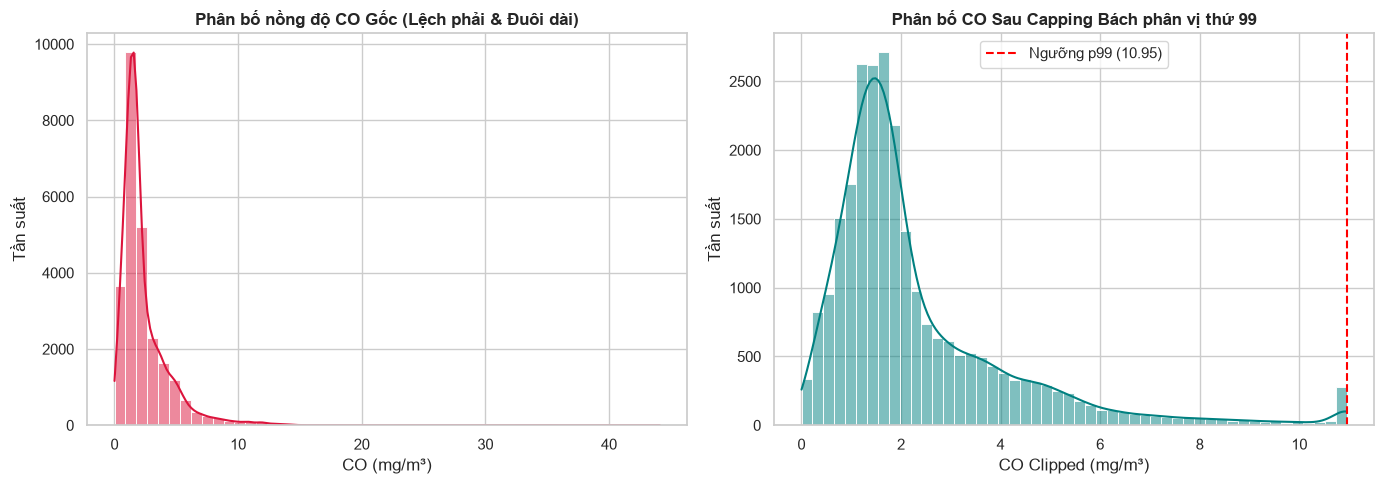

[THÀNH CÔNG] Đã xuất: hinh_1_phan_bo_co.png


In [17]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Tạo thư mục lưu hình ảnh sắc nét
FIG_DIR = BASE_DIR / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình font và giao diện đồ thị
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
sns.set_theme(style="whitegrid")

# ==========================================
# HÌNH 1: Phân bố của CO (Trước và Sau Capping)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# CO Gốc
sns.histplot(train_df["CO"], kde=True, ax=axes[0], color="crimson", bins=50)
axes[0].set_title(
    "Phân bố nồng độ CO Gốc (Lệch phải & Đuôi dài)", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("CO (mg/m³)")
axes[0].set_ylabel("Tần suất")

# CO Sau Capping p99
sns.histplot(
    train_df["CO_clipped"], kde=True, ax=axes[1], color="teal", bins=50
)
axes[1].axvline(
    co_p99_threshold,
    color="red",
    linestyle="--",
    label=f"Ngưỡng p99 ({co_p99_threshold:.2f})",
)
axes[1].set_title(
    "Phân bố CO Sau Capping Bách phân vị thứ 99", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("CO Clipped (mg/m³)")
axes[1].set_ylabel("Tần suất")
axes[1].legend()

plt.tight_layout()
plt.savefig(
    FIG_DIR / "hinh_1_phan_bo_co.png", dpi=300, bbox_inches="tight"
)
plt.show()
print("[THÀNH CÔNG] Đã xuất: hinh_1_phan_bo_co.png")

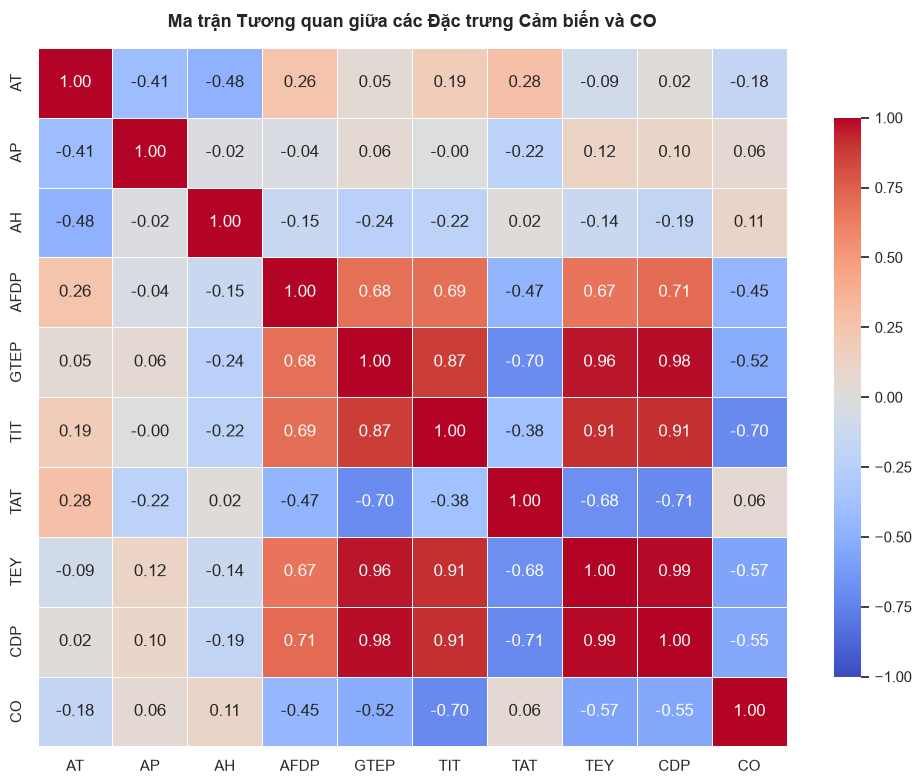

[THÀNH CÔNG] Đã xuất: hinh_2_ma_tran_tuong_quan.png


In [18]:
# ==========================================
# HÌNH 2: Ma trận tương quan (Correlation Heatmap)
# ==========================================
plt.figure(figsize=(10, 8))
corr_matrix = train_df[feature_cols + ["CO"]].corr()

# Vẽ heatmap với mặt nạ tam giác trên (tùy chọn cho gọn)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title(
    "Ma trận Tương quan giữa các Đặc trưng Cảm biến và CO",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()
plt.savefig(
    FIG_DIR / "hinh_2_ma_tran_tuong_quan.png", dpi=300, bbox_inches="tight"
)
plt.show()
print("[THÀNH CÔNG] Đã xuất: hinh_2_ma_tran_tuong_quan.png")


--- BẢNG GIÁ TRỊ VIF TỪNG BIẾN ---
Feature        VIF
    TEY 253.877471
    CDP 250.343859
    TIT  38.135179
   GTEP  29.060675
    TAT  10.244232
     AT   8.247168
   AFDP   2.513322
     AH   1.561170
     AP   1.511158


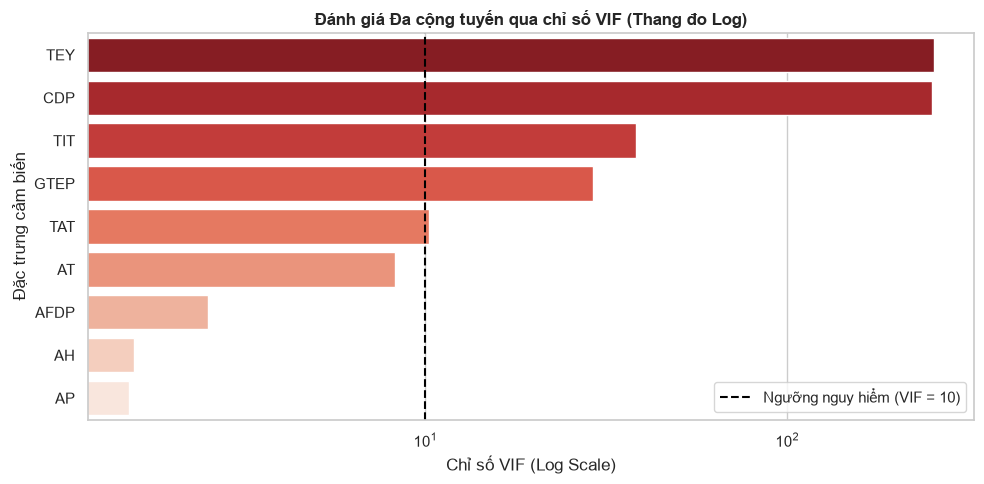

[THÀNH CÔNG] Đã xuất: hinh_3_bang_danh_gia_vif.png


In [19]:
# ==========================================
# BẢNG 1 & HÌNH: Tính VIF từng biến (Biểu đồ cột)
# ==========================================
# Chuẩn bị dữ liệu tính VIF trên các biến gốc chưa scale
X_vif = train_df[feature_cols].dropna()

vif_data = pd.DataFrame()
vif_data["Feature"] = feature_cols
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(len(feature_cols))
]
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(
    drop=True
)

print("\n--- BẢNG GIÁ TRỊ VIF TỪNG BIẾN ---")
print(vif_data.to_string(index=False))

# Vẽ biểu đồ VIF dạng cột để chèn báo cáo
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=vif_data, x="VIF", y="Feature", palette="Reds_r", hue="Feature"
)
plt.axvline(
    x=10,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Ngưỡng nguy hiểm (VIF = 10)",
)
plt.xscale("log")  # Dùng log scale vì VIF lớn vượt trội
plt.title(
    "Đánh giá Đa cộng tuyến qua chỉ số VIF (Thang đo Log)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Chỉ số VIF (Log Scale)")
plt.ylabel("Đặc trưng cảm biến")
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "hinh_3_bang_danh_gia_vif.png", dpi=300, bbox_inches="tight"
)
plt.show()
print("[THÀNH CÔNG] Đã xuất: hinh_3_bang_danh_gia_vif.png")

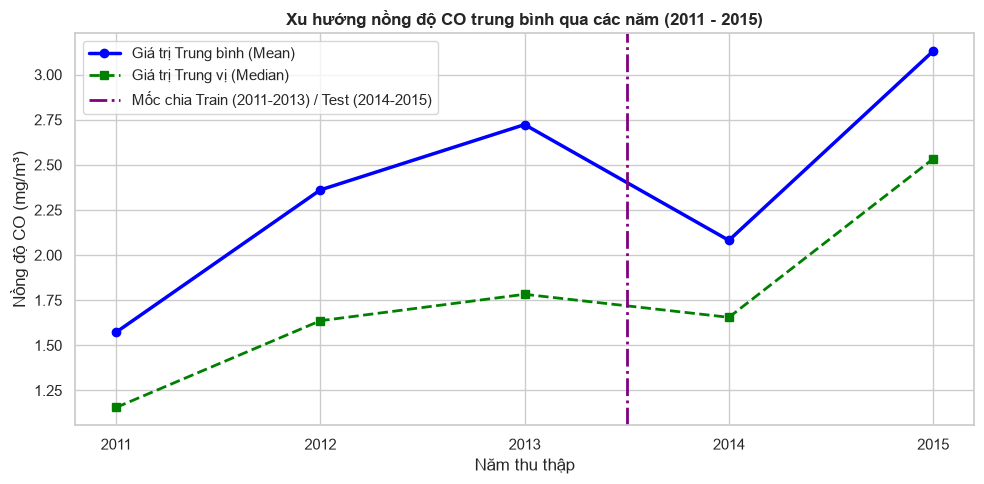

[THÀNH CÔNG] Đã xuất: hinh_4_co_drift_by_year.png


In [20]:
# ==========================================
# HÌNH 4: Xu hướng CO theo thời gian (Data Drift theo năm)
# ==========================================
plt.figure(figsize=(10, 5))

# Tính trung bình và độ lệch chuẩn của CO theo từng năm trên df gốc
yearly_stats = (
    df.groupby("year")["CO"]
    .agg(["mean", "median", "std"])
    .reset_index()
)

plt.plot(
    yearly_stats["year"],
    yearly_stats["mean"],
    marker="o",
    linewidth=2.5,
    color="blue",
    label="Giá trị Trung bình (Mean)",
)
plt.plot(
    yearly_stats["year"],
    yearly_stats["median"],
    marker="s",
    linestyle="--",
    linewidth=2,
    color="green",
    label="Giá trị Trung vị (Median)",
)

plt.axvline(
    x=2013.5,
    color="purple",
    linestyle="-.",
    linewidth=2,
    label="Mốc chia Train (2011-2013) / Test (2014-2015)",
)
plt.title(
    "Xu hướng nồng độ CO trung bình qua các năm (2011 - 2015)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Năm thu thập")
plt.ylabel("Nồng độ CO (mg/m³)")
plt.xticks([2011, 2012, 2013, 2014, 2015])
plt.legend()

plt.tight_layout()
plt.savefig(
    FIG_DIR / "hinh_4_co_drift_by_year.png", dpi=300, bbox_inches="tight"
)
plt.show()
print("[THÀNH CÔNG] Đã xuất: hinh_4_co_drift_by_year.png")